# Explore > 'Life Ladder' (TARGET)

> information about how happy people are (happiness score)

# Imports

In [1]:
import matplotlib.pyplot as plt
from scipy import stats

from Q1_OLD.consts import *

from utils.read_csv_to_df import read_csv_to_df
from utils.plot_hist_with_normal_dist_overlay import plot_hist_with_normal_dist_overlay
from utils.rule_of_thumb__skewness import rule_of_thumb__skewness
from utils.rule_of_thumb__kurtosis import rule_of_thumb__kurtosis

# Defaults

In [2]:
COLUMN = columns['LL']

# Fetch Data

In [3]:
train_df = read_csv_to_df(path=TRAIN_PATH)

---

# Summary

In [4]:
train_df[COLUMN].info()
TARGET_stats = train_df[[COLUMN]].describe().T

q1, q3 = train_df[COLUMN].quantile(0.25), train_df[COLUMN].quantile(0.75)
iqr = q3 - q1
TARGET_stats['IQR outliers'] = (
	(train_df[COLUMN] < q1 - 1.5 * iqr) | (train_df[COLUMN] > q3 + 1.5 * iqr)
).sum()

TARGET_stats

<class 'pandas.core.series.Series'>
RangeIndex: 1559 entries, 0 to 1558
Series name: Life Ladder
Non-Null Count  Dtype  
--------------  -----  
1559 non-null   float64
dtypes: float64(1)
memory usage: 12.3 KB


,count,mean,std,min,25%,50%,75%,max,IQR outliers
Life Ladder,1559.0,5.469321,1.11328,2.375,4.6495,5.374,6.2725,8.019,0


# Plots

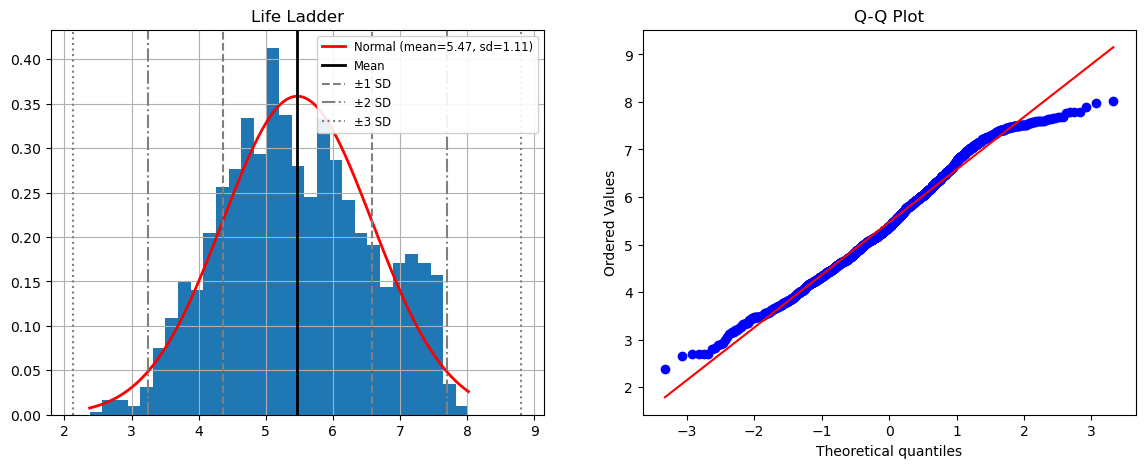

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_hist_with_normal_dist_overlay(
    series=train_df[COLUMN],
    bins=HIST_BINS,
    ax=ax1
)

stats.probplot(
	train_df[COLUMN],
	dist="norm",
	plot=ax2)
ax2.set_title("Q-Q Plot")

plt.show()

# Skew & Kurtosis

In [6]:
LifeLadderSkew = train_df[COLUMN].skew()
LifeLadderSkew_RuleOfThumb = rule_of_thumb__skewness(series=train_df[COLUMN])
LifeLadderKurtosis = train_df[COLUMN].kurt()
LifeLadderKurtosis_RuleOfThumb = rule_of_thumb__kurtosis(series=train_df[COLUMN])

print(f'{COLUMN} Skew: {LifeLadderSkew:.3f} -> {LifeLadderSkew_RuleOfThumb}')
print(f'{COLUMN} Kurtosis: {LifeLadderKurtosis:.3f} -> {LifeLadderKurtosis_RuleOfThumb}')

Life Ladder Skew: 0.075 -> Roughly symmetric
Life Ladder Kurtosis: -0.670 -> Mesokurtic (near-normal tails)


---

### Notes / Observations
#### General
- No missing values (1559 of 1559 rows) and no IQR outliers.
- Scores run from 2.4 to 8.0, with mean 5.47 and median 5.37 (very close, so little skew).
- The histogram is close to a bell curve (skew 0.07), with a small second bump around 7.0 to 7.5 from a group of very happy countries.
- The QQ plot is straight through the middle but flattens at both ends: there are fewer extreme scores than a true normal curve would predict (light tails, kurtosis -0.67).
- **Takeaway:** the target is well behaved and ready to model as is.

#### Transforming
- Not needed: skew (0.07) and kurtosis (-0.67) are both inside the "normal" rule of thumb ranges.
- Leaving it untransformed keeps predictions and errors (RMSE, MAE) in Life Ladder points, which is easier to read.

#### Scaling
- Not needed. Scaling the target only changes the units of the coefficients and errors, not the fit.

#### Imputing
- Nothing to impute, so no rows have to be dropped because of the target.